Numerator Coefficients before bilinear transform: [1.]
Denominator Coefficients before bilinear transform: [1.         2.61312593 3.41421356 2.61312593 1.        ]
center angular frequency: 47653.01 and width: 16345.32 rad/s
Numerator Coefficients bandpass filter: [7.13795888e+16 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00]
Denominator Coefficients bandpass filter: [1.00000000e+00 4.27123877e+04 9.99541039e+09 3.02386486e+14
 3.51535693e+19 6.86661980e+23 5.15420725e+28 5.00144758e+32
 2.65902546e+37]
Numerator Coefficients after bilinear transform: [ 2.91365792e-04  0.00000000e+00 -1.16546317e-03 -6.37059305e-19
  1.74819475e-03  6.37059305e-19 -1.16546317e-03  0.00000000e+00
  2.91365792e-04]
Denominator Coefficients after bilinear transform: [  1.          -3.97732492   9.20580098 -13.7420647   14.8337634
 -11.40091569   6.3355541   -2.26917168   0.47350645]


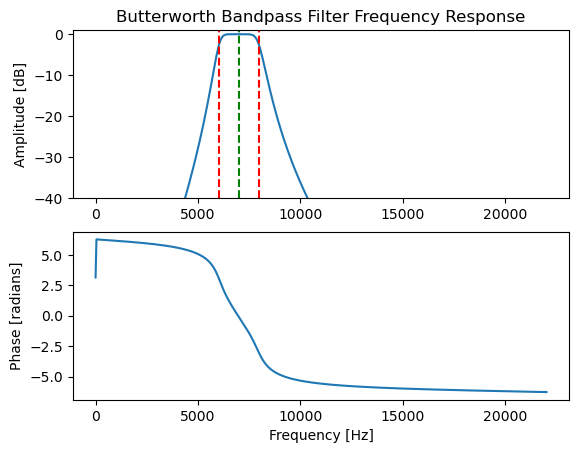

In [10]:
from Bandpass_filter import *
import matplotlib.pyplot as plt
import scipy.signal as signal

passband_1 = 6e3
passband_2 = 8e3

fs = 44100  # sampling frequency

#signal.bilinear(b, a, fs=1.0) #
order = 4  # filter order

b, a = design_analog_lp_prototype(order)

print("Numerator Coefficients before bilinear transform:", b)
print("Denominator Coefficients before bilinear transform:", a)

omega_passband1 = prewarp_frequency(passband_1, fs)
omega_passband2 = prewarp_frequency(passband_2, fs)

omega_passband_center = np.sqrt(omega_passband1 * omega_passband2)
omega_passband_width = omega_passband2 - omega_passband1

print(f"center angular frequency: {omega_passband_center:.2f} and width: {omega_passband_width:.2f} rad/s")

b,a = signal.lp2bp(b, a, omega_passband_center, omega_passband_width)  # convert to bandpass filter

print("Numerator Coefficients bandpass filter:", b)
print("Denominator Coefficients bandpass filter:", a)

b,a = signal.bilinear(b, a, fs=fs)
print("Numerator Coefficients after bilinear transform:", b)
print("Denominator Coefficients after bilinear transform:", a)


# evualute the frequency response of the filter
w, h = signal.freqz(b, a, fs=fs)

# bode plot
plt.figure()
A = 20 * np.log10(abs(h))
plt.subplot(2, 1, 1)
plt.plot(w, A)
plt.title('Butterworth Bandpass Filter Frequency Response')
plt.ylabel('Amplitude [dB]')
plt.ylim(-40, 1)
plt.axvline(7e3, color='green', linestyle='--') # vertical line at 7 kHz
plt.axvline(6e3, color='red', linestyle='--') # vertical line at 6 kHz
plt.axvline(8e3, color='red', linestyle='--') # vertical line at 8 kHz

plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(h)))

plt.xlabel('Frequency [Hz]')
plt.ylabel('Phase [radians]')
plt.show() 

